# MC2 · Augmentation · Day 1 – Data & Domain
**Country:** Japan · **Topic:** Night-time festival photography (Akita Kanto Festival)

*Scope of this day: define use case, problem, image, structure of interest and objective. No augmentation methods are introduced or applied.*

## 1. Use case
The **Akita Kanto Festival** (Akita City, Japan, 3–6 August) is a night festival in which performers balance tall bamboo poles (*kanto*) carrying up to 46 paper lanterns (*chōchin*) each. The lanterns carry lettering (neighbourhood association names, sponsor names such as "ALSOK") and a red crest.

Heritage archives, the tourism board and visitor apps would like to **automatically recognise which lantern towers and lantern markings appear in visitor night photos**, e.g. for cataloguing, searching photos by team or sponsor, and counting lanterns per tower.

## 2. Problem statement
- **Scarce, uniform data:** the festival takes place on only four evenings a year, so labelled images are rare and mostly show the same few viewpoints and the same night lighting.
- **Difficult imaging conditions:**
  - extreme dynamic range: self-illuminated lanterns against an almost black sky;
  - low light forces high ISO, which causes sensor noise, most visible in dark regions;
  - glow/blooming around bright lanterns reduces the contrast of thin lettering;
  - swaying poles and moving performers cause motion blur in handheld or long exposures;
  - mixed warm lantern light and neon/shop lighting create colour casts.
- **Domain shift:** a model trained on a few photos will not generalise to other cameras, exposure settings, weather (humidity, haze) or capture time (dusk vs. late night).

Augmentation is therefore needed to simulate realistic variation in capture conditions and increase the variability of the data.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMG_PATH = "akita-kanto-festival-by-annintofu-flickr-2187739691.jpg"
img = np.array(Image.open(IMG_PATH).convert("RGB"))
H, W, C = img.shape
print(f"shape: {img.shape}, dtype: {img.dtype}, range: [{img.min()}, {img.max()}]")

shape: (1366, 2048, 3), dtype: uint8, range: [0, 255]


## 3. Selected image
**Origin:** photograph "Akita Kanto Festival" by *annintofu*, Flickr (file `akita-kanto-festival-by-annintofu-flickr-2187739691.jpg`).
Found via Bunnik Tours photo gallery (https://www.bunniktours.com.au/tools/photo-gallery/asia-incl-india-and-sri-lanka/colours-of-northern-japan-kanto-and-nebuta-festivals-2026), credited there as "Akita Kanto Festival in Akita, Japan by Annintofu/Flickr". No licence is stated on that page and the original Flickr page could not be located; the image is used here for non-commercial coursework only, with attribution.

**Content:** night scene, wide-angle shot from a low viewpoint looking up. Two large lantern towers dominate the foreground (left: black "ALSOK" lettering; right: red Akita crest, association-name lanterns at the top). Two more towers are tilted in perspective on the right. Performers in happi coats stand in the foreground, some carrying small lanterns. Shop and convenience-store signs are visible in the background; the sky is black.

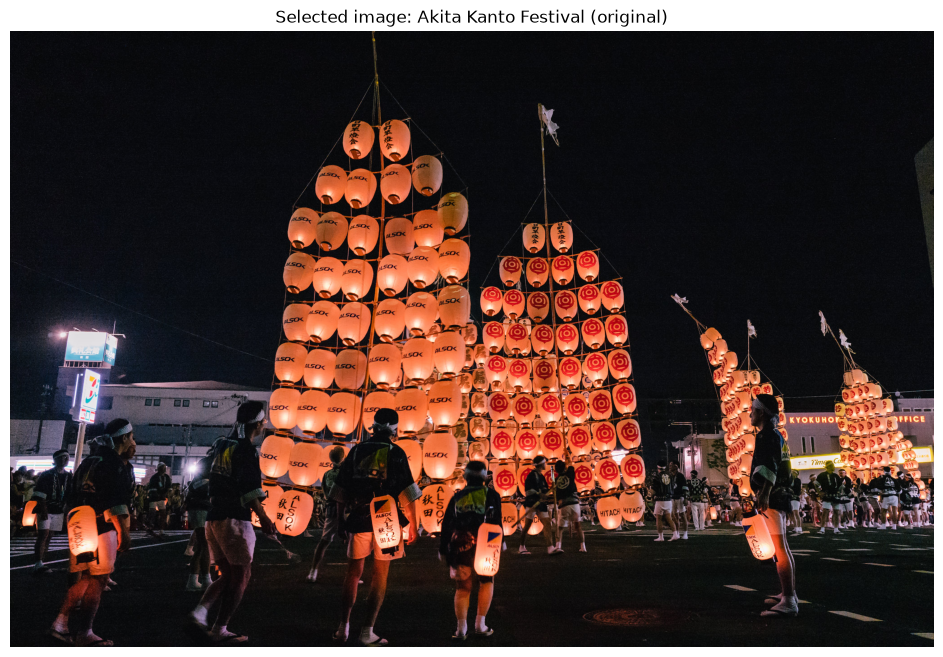

In [12]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img)
ax.set_title("Selected image: Akita Kanto Festival (original)")
ax.axis("off")
plt.show()

**Plot explanation – original image.** Full-resolution view of the selected photo (2048×1366 px, RGB). It shows the setting the whole challenge is based on: bright, self-lit lantern towers against a nearly black sky, with dark foreground silhouettes. Even at this scale, noise in the dark regions and the glow around the lanterns are visible.

### Relevant visual structures
- **Regular grid** of bright, nearly identical ellipses (lantern rows and columns) with thin dark horizontal bamboo crossbars.
- **Thin dark lettering** (kanji and Latin) on bright paper: edge-defined, high-frequency content.
- **Red circular crest** on orange paper: colour and shape contrast.
- **Smooth glowing gradients** inside each lantern with a brighter rim around the opening.
- **Large uniform dark areas** (sky) where noise is most visible.
- **Sharp silhouettes** of performers in the foreground.

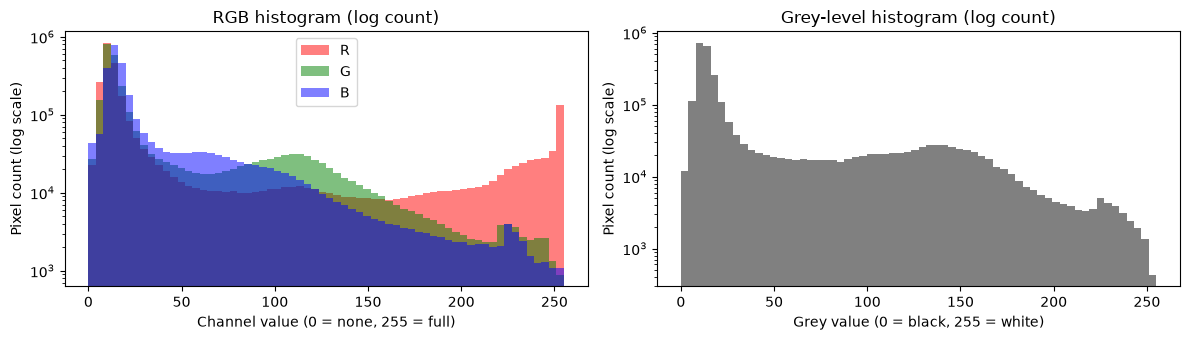

share of pixels with mean intensity < 30: 69.8%
share of pixels with mean intensity > 225: 0.7%


In [13]:
gray = img.mean(axis=2)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for i, (c, name) in enumerate(zip("rgb", ["R", "G", "B"])):
    axs[0].hist(img[..., i].ravel(), bins=64, color=c, alpha=0.5, label=name)
axs[0].set_yscale("log"); axs[0].set_title("RGB histogram (log count)"); axs[0].legend()
axs[1].hist(gray.ravel(), bins=64, color="gray"); axs[1].set_yscale("log")
axs[1].set_title("Grey-level histogram (log count)")
axs[0].set_xlabel("Channel value (0 = none, 255 = full)")
axs[1].set_xlabel("Grey value (0 = black, 255 = white)")
for a in axs: a.set_ylabel("Pixel count (log scale)")
plt.tight_layout(); plt.show()
print(f"share of pixels with mean intensity < 30: {(gray < 30).mean():.1%}")
print(f"share of pixels with mean intensity > 225: {(gray > 225).mean():.1%}")

**Plot explanation – histograms (log-scaled counts).** Left: histogram per colour channel; right: grey-level histogram (mean of R, G, B). The y-axis is logarithmic, so the small bright regions remain visible next to the huge dark mass.
- A very tall peak at low values (about 10–20) is the black sky and shadows (≈70 % of pixels below 30).
- A broad second mode around 120–160 is the lantern paper; it is not a narrow peak but spreads across the mid-tones.
- The red channel (left plot) piles up at 255: the warm lantern light clips in R, which flattens detail and lets the glow bleed. Green and blue stay lower, which explains the orange colour cast.
- Together this is a very wide dynamic range with a strong dark peak and clipping in one channel: the exposure situation that makes lettering fragile.

## 4. Structure of interest
**Chosen structure:** the black **"ALSOK" lettering on the lanterns of the left tower.**

**Why:** it is thin, high-frequency, edge-defined content on a bright, glowing background, so it is the first thing lost under capture degradation. It is also a clearly bounded structure that can be reused in later days (edges, segmentation).

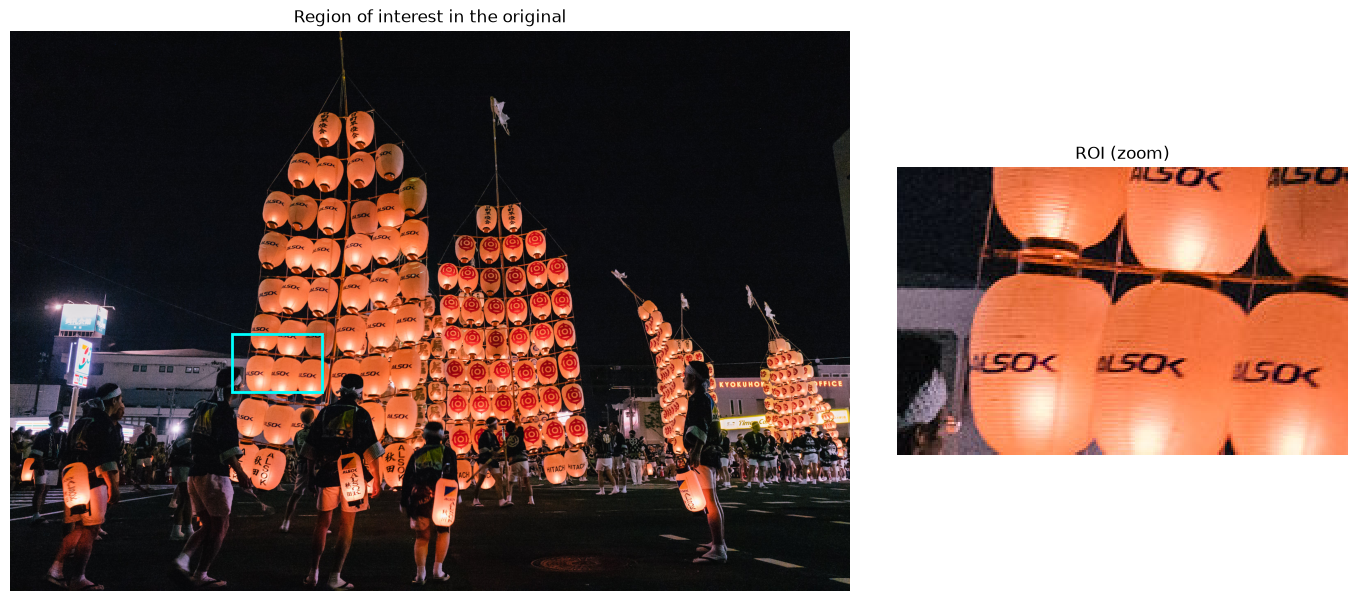

In [14]:
# Region of interest: approximate crop around one "ALSOK" lantern in the left tower.
# Coordinates refer to the 2048x1366 original; adjust after viewing the figure below.
x0, x1 = 540, 760
y0, y1 = 740, 880

fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2, 1]})
axs[0].imshow(img)
axs[0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=2))
axs[0].set_title("Region of interest in the original"); axs[0].axis("off")
axs[1].imshow(img[y0:y1, x0:x1], interpolation="nearest")
axs[1].set_title("ROI (zoom)"); axs[1].axis("off")
plt.tight_layout(); plt.show()

**Plot explanation – region of interest.** Left: the original with the ROI (cyan rectangle, x 540–760, y 740–880) on the lower part of the left tower. Right: the same ROI enlarged with nearest-neighbour interpolation, so individual pixels are visible. It contains three lanterns with the black "ALSOK" lettering. Visible in the zoom: strokes only a few pixels wide, a slightly noisy and blocky texture (JPEG compression and sensor noise), and a bright glow near the lantern centres. This is the structure the augmentation objective refers to.

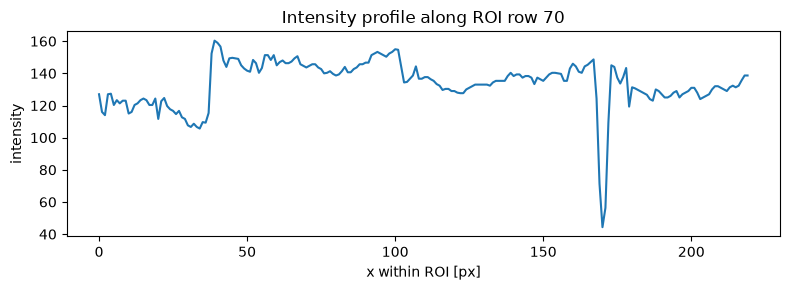

ROI mean: 121.6, min: 0.0, max: 243.3


In [15]:
# Intensity profile across the lettering (one horizontal line through the ROI).
# This only describes the image; no processing is applied.
roi = img[y0:y1, x0:x1].mean(axis=2)
row = roi.shape[0] // 2
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(roi[row]); ax.set_xlabel("x within ROI [px]"); ax.set_ylabel("intensity")
ax.set_title(f"Intensity profile along ROI row {row}")
plt.tight_layout(); plt.show()
print(f"ROI mean: {roi.mean():.1f}, min: {roi.min():.1f}, max: {roi.max():.1f}")

**Plot explanation – intensity profile.** Mean intensity along one horizontal row through the ROI (row 70, x = 0–220 px). Most of the row lies at about 120–160, which is the glowing paper. Two features stand out:
- A step at x ≈ 38 (≈ 107 → 160): the boundary between two lanterns / a lantern and its surroundings.
- A narrow dip down to ≈ 45 at x ≈ 170, only about 5–10 px wide: a stroke of the lettering. Its contrast against the paper is roughly 90–100 grey levels.

The lettering is therefore a thin, high-contrast feature on a bright background. Noise, blur or a change in exposure would change the width and depth of this dip first, which is why it is a good indicator for the later days. The small fluctuations of ±5–10 levels along the paper are existing noise and texture.

### How the challenge manifests in this structure
- **Contrast depends on exposure:** when the paper saturates, glow bleeds into the strokes and thins or removes them.
- **Noise and slight motion blur** disturb stroke edges that are only a few pixels wide.
- **Perspective** from the low camera angle distorts letter shapes towards the top of the tower.
- **Near-identical neighbours:** all lanterns look alike, so small degradations in the lettering are what separate one team or sponsor from another.

Because there are only a few such photos, the lettering appears under very few capture conditions in the data.

## 5. Objective of augmentation
Increase the variability of the training images by **simulating realistic night-capture degradations** (different sensor noise levels, exposure and contrast of the glowing lanterns, softness of the lettering), so that a recognition model **remains robust on thin lettering and crest edges under capture conditions not covered by the few original photos**.

Augmented images must remain plausible as real festival photos and must not change the *identity* of the content (the text must still read as the same text). Degradation that makes the structure unrecognisable defeats the purpose.